# Learning the MQMQA with Hephaestus

A slag or a salt melt is not a random mixture of ions. Silicon in a silicate melt prefers iron or
magnesium as its second neighbour, and that preference, the short-range order, sets the energy
of the melt and so which solid crystallizes from it and at what temperature. The modified
quasichemical model in the quadruplet approximation (MQMQA) describes the melt by counting
quadruplets, groups of two cations and two anions, and lets those counts relax to the
arrangement of lowest Gibbs energy.

This notebook works through the model with the open databases that ship with Hephaestus. Every
number comes from the same engine the browser calculator runs. You will

1. open a database and see what it holds,
2. watch the short-range order form along the FeO-SiO2 join,
3. change one parameter and see what it does,
4. follow a slag as it cools and crystallizes,
5. read the model in TDB notation.

Run it from the repository root after building the engine (`bash scripts/build.sh`). The
companion primer for readers who do not program is `paper/Supplementary_S1_primer.pdf`.

In [1]:
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np

ROOT = Path.cwd()
while not (ROOT / "python" / "mqmqa").is_dir() and ROOT != ROOT.parent:
    ROOT = ROOT.parent
sys.path.insert(0, str(ROOT / "python"))

import mqmqa
from mqmqa import equilibrium as eqm
from mqmqa import gem

FEO_SIO2 = ROOT / "data" / "feo-sio2" / "FeO-SiO2-liquid.dat"
FMS = ROOT / "data" / "feo-mgo-sio2" / "FeO-MgO-SiO2-combined.dat"
CFMS = ROOT / "data" / "cao-feo-mgo-sio2" / "CaO-FeO-MgO-SiO2-combined.dat"


## 1. What a slag database holds

The FeO-SiO2 liquid has two cations, Fe2+ and Si4+, and one anion, O2-. Each cation-anion pair
carries a Gibbs energy taken from the pure oxide liquids. The coordination numbers say how many
second neighbours each ion has, and the excess terms are the fitted part, the energy of putting
an Fe and an Si next to each other on the same oxygen.

In [2]:
db = mqmqa.Database.read(FEO_SIO2)
p = db.phase_index(db.phase_names[0])
print("phase:", db.phase_names[0])
print("cations:", db.cations(p), " anions:", db.anions(p))
xs = db.mqmx(p, 1873.0)
print(len(xs["L"]), "excess terms at 1873 K:")
for k in range(len(xs["L"])):
    code_ = "QGBR"[xs["code"][k]]
    print(f"  {code_} term, exponents ({xs['p'][k]},{xs['q'][k]}): {xs['L'][k]:12.1f} J/mol")

phase: FEO-SIO2-LIQUID
cations: [{'name': 'FE+2', 'charge': 2.0, 'group': 1}, {'name': 'SI+4', 'charge': 4.0, 'group': 1}]  anions: [{'name': 'O', 'charge': 2.0, 'group': 1}]
4 excess terms at 1873 K:
  Q term, exponents (0,0):      16708.7 J/mol
  Q term, exponents (1,0):     -28132.9 J/mol
  Q term, exponents (0,3):     -24367.9 J/mol
  Q term, exponents (0,5):     102533.0 J/mol


## 2. Short-range order along the FeO-SiO2 join

At each composition the engine finds the quadruplet fractions that minimize the Gibbs energy. The
fraction of mixed (Fe,Si) quadruplets peaks near the orthosilicate composition, 2FeO.SiO2
(x(SiO2) = 1/3), where every silicon is surrounded by iron. To see how much of that comes from the
fitted excess terms, the same calculation is repeated with every excess coefficient set to zero.

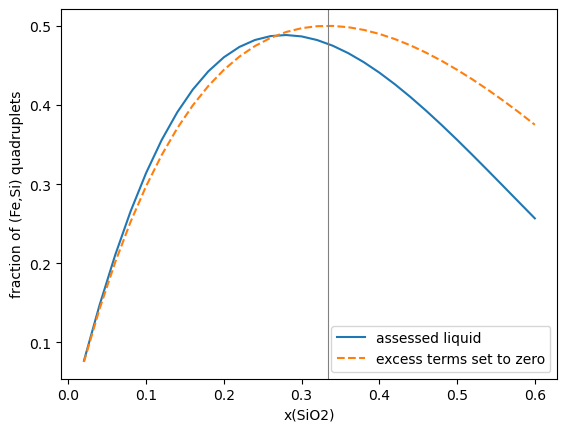

In [3]:
T = 1873.0
cat = db.cations(p)
ca, cb, ax, ay = mqmqa.enumerate_quadruplets(len(cat), len(db.anions(p)))
mixed = [q for q in range(len(ca)) if ca[q] != cb[q]]

def mixed_fraction(database, x_sio2):
    inp = eqm.build_inputs(database, p, T, components=["FE", "SI", "O"])
    fe, si = 1 - x_sio2, x_sio2
    o = fe + 2 * si
    tot = fe + si + o
    r = mqmqa.c_equilibrate(inp, {"FE": fe / tot, "SI": si / tot, "O": o / tot})
    return sum(r["X"][q] for q in mixed), r["GM"]

xgrid = np.linspace(0.02, 0.6, 30)
with_terms = [mixed_fraction(db, x)[0] for x in xgrid]

bare = mqmqa.Database.read(FEO_SIO2)
for q in bare.params():
    bare.set_param(q["index"], 0.0)
without_terms = [mixed_fraction(bare, x)[0] for x in xgrid]

plt.plot(xgrid, with_terms, label="assessed liquid")
plt.plot(xgrid, without_terms, "--", label="excess terms set to zero")
plt.axvline(1 / 3, color="grey", lw=0.8)
plt.xlabel("x(SiO2)")
plt.ylabel("fraction of (Fe,Si) quadruplets")
plt.legend()
plt.show()

## 3. Change one number

`set_param` changes a coefficient in memory, and the next calculation uses it. Here the constant
part of the first excess term is halved, and the Gibbs energy of mixing along the join moves with
it. This is the same operation the database fitter performs thousands of times.

term 0, constant part: -58713.8 -> -29356.9 J/mol


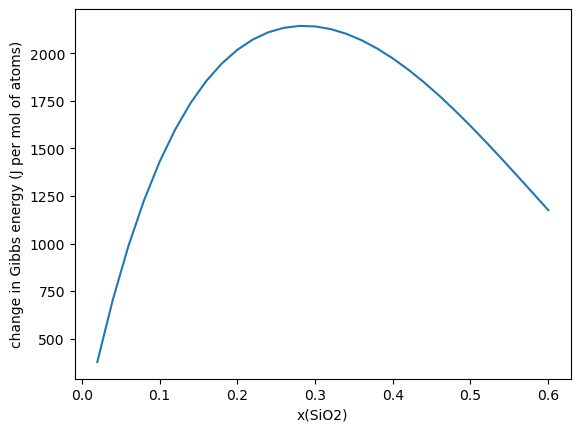

In [4]:
def gm_curve(database):
    return [mixed_fraction(database, x)[1] for x in xgrid]

g_assessed = gm_curve(db)
edited = mqmqa.Database.read(FEO_SIO2)
q = next(q for q in edited.params() if q["tfun"] == 1)
edited.set_param(q["index"], 0.5 * q["value"])
print(f"term {q['term']}, constant part: {q['value']:.1f} -> {0.5 * q['value']:.1f} J/mol")
g_edited = gm_curve(edited)

plt.plot(xgrid, np.array(g_edited) - np.array(g_assessed))
plt.xlabel("x(SiO2)")
plt.ylabel("change in Gibbs energy (J per mol of atoms)")
plt.show()

## 4. A slag cooling: which solids form, and when

The equilibrium solver takes any number of elements and every phase in the database, here the
FeO-MgO-SiO2 liquid, olivine, orthopyroxene, magnesiowustite and cristobalite, and finds the
stable assemblage at each temperature. As this slag cools, olivine appears first and the liquid
shrinks.

1873 K: FEO-MGO-SIO2-LIQUID 1.000


1823 K: FEO-MGO-SIO2-LIQUID 0.897, OLIVINE 0.103


1773 K: FEO-MGO-SIO2-LIQUID 0.730, OLIVINE 0.270


1723 K: OLIVINE 0.390, FEO-MGO-SIO2-LIQUID 0.610


1673 K: FEO-MGO-SIO2-LIQUID 0.519, OLIVINE 0.481


1623 K: FEO-MGO-SIO2-LIQUID 0.407, OLIVINE 0.593


1573 K: FEO-MGO-SIO2-LIQUID 0.287, OLIVINE 0.713


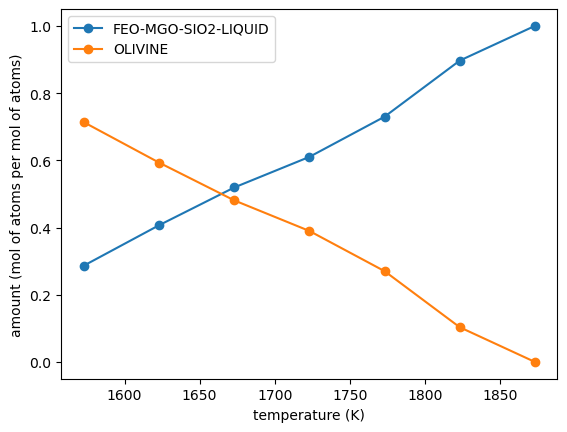

In [5]:
fms = mqmqa.Database.read(FMS)
cations = {"FE": 0.4, "MG": 0.3, "SI": 0.3}
amounts = dict(cations, O=cations["FE"] + cations["MG"] + 2 * cations["SI"])
temps = np.arange(1873.0, 1572.0, -50.0)
history = {}
for T_ in temps:
    r = gem.equilibrium(fms, T_, amounts)
    for s in r.sets:
        history.setdefault(s.phase, {})[T_] = history.get(s.phase, {}).get(T_, 0.0) + s.amount
    print(f"{T_:.0f} K: " + ", ".join(f"{s.phase} {s.amount:.3f}" for s in r.sets))

for phase, series in history.items():
    plt.plot(temps, [series.get(T_, 0.0) for T_ in temps], "o-", label=phase)
plt.xlabel("temperature (K)")
plt.ylabel("amount (mol of atoms per mol of atoms)")
plt.legend()
plt.show()

## 5. The same model in TDB notation

The engine writes any ChemSage database as a uTDB file, in which every pair energy, coordination
number and excess term of the liquid is a named statement in the notation of alloy CALPHAD
databases. Change one value in the file, reload it in the browser calculator, and watch the
diagram respond.

In [6]:
text = db.write_utdb()
for line in text.splitlines():
    if line.lstrip().startswith(("PARAMETER MQX", "PARAMETER MQZ(")):
        print(line.strip()[:110])

PARAMETER MQZ(FEO-SIO2-LIQUID,FE+2,FE+2:O-2,O-2)  0.01  1.3774438 1.3774438 1.3774438 1.3774438;  100000000000
PARAMETER MQZ(FEO-SIO2-LIQUID,SI+4,SI+4:O-2,O-2)  0.01  2.7548876 2.7548876 1.3774438 1.3774438;  100000000000
PARAMETER MQXQ(FEO-SIO2-LIQUID,FE+2,SI+4:O-2,O-2;0,0)  0.01
PARAMETER MQXQ(FEO-SIO2-LIQUID,FE+2,SI+4:O-2,O-2;1,0)  0.01
PARAMETER MQXQ(FEO-SIO2-LIQUID,FE+2,SI+4:O-2,O-2;0,3)  0.01
PARAMETER MQXQ(FEO-SIO2-LIQUID,FE+2,SI+4:O-2,O-2;0,5)  0.01


## 6. How the solver knows it has finished

At equilibrium the element chemical potentials define a plane, and no phase has any state below
it, because a state below the plane would lower the total Gibbs energy. `gem.driving_force`
searches the liquid for its lowest point against such a plane, its composition free.

The four-oxide slag below is computed twice at 1573 K, once with every phase and once with the
liquid and clinopyroxene held out, which leaves olivine and wollastonite. Against the second
plane the liquid lies hundreds of J/mol below, so that assemblage cannot be the equilibrium.
Against the first, nothing lies below; the solver reports that check as `residual`.

In [7]:
cfms = mqmqa.Database.read(CFMS)
liquid = next(n for n in cfms.phase_names if "LIQUID" in n)
cations = {"CA": 0.20, "FE": 0.05, "MG": 0.35, "SI": 0.40}
amounts = dict(cations, O=cations["CA"] + cations["FE"] + cations["MG"] + 2 * cations["SI"])

full = gem.equilibrium(cfms, 1573, amounts)
held = gem.equilibrium(cfms, 1573, amounts, suspend=[liquid, "CLINOPYROXENE"])
for label, r in [("every phase", full), ("liquid and clinopyroxene held out", held)]:
    lowest = gem.driving_force(cfms, liquid, 1573, r.mu)[0]
    print(f"{label}: " + ", ".join(f"{s.phase} {s.amount:.3f}" for s in r.sets))
    print(f"    G = {r.G:.2f} J/mol, lowest liquid point against its plane {lowest.df:+.3f} J/mol,"
          f" residual {r.residual:+.4f}")

every phase: CAO-FEO-MGO-SIO2-LIQUID 0.497, OLIVINE 0.341, CLINOPYROXENE 0.162
    G = -364069.85 J/mol, lowest liquid point against its plane -0.000 J/mol, residual -0.0000
liquid and clinopyroxene held out: WOLLASTONITE 0.417, OLIVINE 0.583
    G = -364013.48 J/mol, lowest liquid point against its plane -538.059 J/mol, residual -0.0000


## 7. A smaller system from a larger database

A database for CaO-FeO-MgO-SiO2 also describes every system inside it. For a slag with no CaO,
the solver takes the calcium ions out of the liquid (with every quadruplet, pair and excess
term that names them), and the four-oxide file then gives exactly what the FeO-MgO-SiO2 file
gives.

In [8]:
fms = mqmqa.Database.read(FMS)
cations = {"FE": 0.05, "MG": 0.55, "SI": 0.40}
amounts = dict(cations, O=cations["FE"] + cations["MG"] + 2 * cations["SI"])
for label, database in [("CaO-FeO-MgO-SiO2 file", cfms), ("FeO-MgO-SiO2 file", fms)]:
    r = gem.equilibrium(database, 1973, amounts)
    print(f"{label:22s} " + ", ".join(f"{s.phase} {s.amount:.4f}" for s in r.sets) + f"   G = {r.G:.3f} J/mol")

CaO-FeO-MgO-SiO2 file  OLIVINE 0.2520, CAO-FEO-MGO-SIO2-LIQUID 0.7480   G = -377258.874 J/mol


FeO-MgO-SiO2 file      OLIVINE 0.2520, FEO-MGO-SIO2-LIQUID 0.7480   G = -377258.874 J/mol


## 8. Other solution models in ChemSage files

ChemSage files also hold solutions that are not quasichemical: ideal mixtures (IDMX, often the
gas) and Redlich-Kister-Muggianu solutions (RKMP). The engine reads both as one-lattice phases of
species, and a species such as the molecule AB takes its composition from its own record. Below,
an ideal gas of A, B and AB: as the temperature rises the molecule dissociates.

In [9]:
def species(name, stoich, a, b):
    """one species record, G = a + b T up to 6000 K"""
    return (f" {name}\n   4  1    {stoich[0]:.1f}    {stoich[1]:.1f}\n"
            f"  6000.0000   {a}   {b}   0.0   0.0   0.0\n 0.0\n 1 0.0 0.00\n")

gas_file = (" System A-B\n    2    1    3    0\n A                        B\n    10.0    10.0\n"
            "   6   1   2   3   4   5   6\n   6   1   2   3   4   5   6\n GAS\n IDMX\n"
            + species("A", (1, 0), 0.0, -20.0) + species("B", (0, 1), 0.0, -20.0)
            + species("AB", (1, 1), -60000.0, -15.0))
gas = mqmqa.Database.read_string(gas_file)

from scipy.optimize import minimize_scalar
for T_ in (800.0, 1500.0, 2500.0, 4000.0):
    # with equal A and B the gas is fixed by the fraction f of AB molecules
    g_of_f = lambda f: gas.cef_gibbs(0, [(1 - f) / 2, (1 - f) / 2, f], T_)
    f = minimize_scalar(g_of_f, bounds=(1e-12, 1 - 1e-12), method="bounded",
                        options={"xatol": 1e-12}).x
    r = gem.equilibrium(gas, T_, {"A": 0.5, "B": 0.5})
    print(f"{T_:5.0f} K: fraction of AB molecules {f:.4f};  G {g_of_f(f):.2f} J/mol along f,"
          f" {r.G:.2f} from the solver")

  800 K: fraction of AB molecules 0.9065;  G -36282.85 J/mol along f, -36282.85 from the solver
 1500 K: fraction of AB molecules 0.4558;  G -46067.99 J/mol along f, -46067.99 from the solver
 2500 K: fraction of AB molecules 0.1589;  G -67731.24 J/mol along f, -67731.24 from the solver
 4000 K: fraction of AB molecules 0.0663;  G -104897.48 J/mol along f, -104897.48 from the solver


Pressure acts on the gas. Each mole of gas species gains R T ln(P / 1 atm), so lowering
the pressure favours more molecules of gas, here A and B over AB (Le Chatelier).

In [10]:
for P_atm in (1.0, 1e-2, 1e-4):
    def g_of_f(f):
        return (gas.cef_gibbs(0, [(1 - f) / 2, (1 - f) / 2, f], 1500.0)
                + gas.R * 1500.0 * np.log(P_atm) / (1 + f))
    f = minimize_scalar(g_of_f, bounds=(1e-12, 1 - 1e-12), method="bounded",
                        options={"xatol": 1e-12}).x
    r = gem.equilibrium(gas, 1500.0, {"A": 0.5, "B": 0.5}, P=P_atm * 101325.0)
    print(f"{P_atm:g} atm: fraction of AB {f:.4f};  G {g_of_f(f):.2f} J/mol along f, {r.G:.2f} from the solver")

1 atm: fraction of AB 0.4558;  G -46067.99 J/mol along f, -46067.99 from the solver
0.01 atm: fraction of AB 0.0149;  G -96102.74 J/mol along f, -96102.74 from the solver
0.0001 atm: fraction of AB 0.0002;  G -153351.57 J/mol along f, -153351.57 from the solver


Ferromagnetic metals carry a magnetic energy (the Inden-Hillert-Jarl form), set in a
ChemSage file by each species' Curie temperature and moment. Below, one magnetic species
(Curie temperature 1000 K, moment 2) on a BCC lattice: its energy minus the non-magnetic
part the file gives (-1000 - 10 T J/mol) is the magnetic energy, largest well below the
Curie temperature and fading above it.

In [11]:
magnetic_file = (" System A\n    1    1    1    0\n A\n    10.0\n"
                 "   6   1   2   3   4   5   6\n   6   1   2   3   4   5   6\n BCC\n SUBLM\n"
                 "  1.000000    0.400000\n A\n  16  1    1.0\n  6000.0000   -1000.0   -10.0   0.0   0.0   0.0\n"
                 " 0.0\n 1 0.0 0.00\n 1000.0   2.0\n   1\n  1.00000\n   1\n A\n   1\n   0\n   0\n")
magnetic = mqmqa.Database.read_string(magnetic_file)
for T_ in (300.0, 600.0, 900.0, 1000.0, 1200.0, 1600.0):
    print(f"{T_:6.0f} K: magnetic energy {magnetic.cef_gibbs(0, [1.0], T_) - (-1000.0 - 10.0 * T_):9.1f} J/mol")

   300 K: magnetic energy   -5540.4 J/mol
   600 K: magnetic energy   -2970.2 J/mol
   900 K: magnetic energy    -989.6 J/mol
  1000 K: magnetic energy    -608.7 J/mol
  1200 K: magnetic energy    -284.2 J/mol
  1600 K: magnetic energy     -89.5 J/mol


## 9. A liquid of ions, vacancies and neutral molecules

Some liquids run from a metal to a salt or an oxide: a sulfide matte from iron to FeS, a
steel-making liquid from iron to its oxide. ChemSage files describe them with Sundman's
two-sublattice ionic liquid (type SUBI; Sundman, Calphad 15 (1991) 109): cations on one
sublattice; anions, vacancies (Va) and neutral molecules on the other. The numbers of sites
change with composition so the charges balance. With cation charges v_C and anion charges v_A,
the cation sublattice has P = sum of |v_A| y_A + Q y_Va sites and the other has Q = sum of v_C y_C,
so a vacancy carries the charge Q.

Below, an illustrative Fe-S liquid (made-up values, not an assessment): (Fe+2)(S-2, Va). At
the iron end every second-sublattice site is a vacancy and a formula unit holds 2 atoms; at
FeS it holds Fe2S2, 4 atoms.

In [12]:
rec = lambda name, st, a, b: (f" {name}\n   4  1    {st}\n  6000.0000   {a}   {b}   0.0   0.0   0.0\n"
                              " 0.0\n 1 0.0 0.00\n")
fes = mqmqa.Database.read_string(
    " System Fe-S\n    2    1    2    0\n Fe                       S\n    55.8    32.1\n"
    "   6   1   2   3   4   5   6\n   6   1   2   3   4   5   6\n LIQ\n SUBI\n"
    + rec("FE+2:S-2", "2.0    2.0", -330000.0, 60.0) + rec("FE+2:VA", "1.0    0.0", 12000.0, -10.0)
    + "   1   2\n FE+2\n S-2  VA\n   2\n   2.0\n   -2.0  -1.0\n   1 1\n   1 2\n"
    + "   3\n   1   2   3   1\n  -40000.0  0 0 0 0 0\n   0\n")
for y_s in (0.0, 0.25, 0.5, 0.75, 1.0):
    g, n = fes.ionic_gibbs(0, [1.0, y_s, 1.0 - y_s], 1500.0)
    atoms = sum(n.values())
    print(f"y_S {y_s:4.2f}: {atoms:.2f} atoms per formula, x_S {n['S'] / atoms:.3f}, "
          f"G {g / atoms:10.1f} J per mole of atoms")

y_S 0.00: 2.00 atoms per formula, x_S 0.000, G    -3000.0 J per mole of atoms
y_S 0.25: 2.50 atoms per formula, x_S 0.200, G   -34410.6 J per mole of atoms
y_S 0.50: 3.00 atoms per formula, x_S 0.333, G   -50096.5 J per mole of atoms
y_S 0.75: 3.50 atoms per formula, x_S 0.429, G   -58007.6 J per mole of atoms
y_S 1.00: 4.00 atoms per formula, x_S 0.500, G   -60000.0 J per mole of atoms


Sundman built the model so that, without anions, a parameter from an ordinary substitutional
solution can be used unchanged: in (Fe+2)(Va, C), the iron-carbon parameter L(Fe+2:Va,C) adds
x_Fe x_C L per mole of atoms, with x_Fe = y_Va (his eq. 15). That holds only with his "rule of
pairs", which multiplies each cation fraction by the vacancy fraction in such terms. The check
below computes the excess both ways. (pycalphad's ionic liquid gives x_Fe^2 x_C L here, one
factor y_Va more; the tests record that difference.)

In [13]:
def fe_c(L):
    ex = f"   3\n   1   2   3   1\n  {L}  0 0 0 0 0\n" if L else ""
    return mqmqa.Database.read_string(
        " System Fe-C\n    2    1    2    0\n Fe                       C\n    55.8    12.0\n"
        "   6   1   2   3   4   5   6\n   6   1   2   3   4   5   6\n LIQ\n SUBI\n"
        + rec("FE+2:VA", "1.0    0.0", -1000.0, 0.0) + rec("C     *   2.00", "0.0    2.0", -4000.0, 0.0)
        + "   1   2\n FE+2\n VA  C\n   2\n   2.0\n   -1.0  0.0\n   1 1\n   1 2\n" + ex + "   0\n")

with_L, without_L = fe_c(10000.0), fe_c(0.0)
for x_c in (0.1, 0.3, 0.5):
    y = [1.0, 1.0 - x_c, x_c]
    per_atom = [g / sum(n.values()) for g, n in (with_L.ionic_gibbs(0, y, 1500.0), without_L.ionic_gibbs(0, y, 1500.0))]
    print(f"x_C {x_c}: excess {per_atom[0] - per_atom[1]:8.2f} J/mol, x_Fe x_C L = {(1 - x_c) * x_c * 10000.0:8.2f}")

x_C 0.1: excess   900.00 J/mol, x_Fe x_C L =   900.00
x_C 0.3: excess  2100.00 J/mol, x_Fe x_C L =  2100.00
x_C 0.5: excess  2500.00 J/mol, x_Fe x_C L =  2500.00


With no iron at all the model still has a liquid. If the second sublattice holds only neutrals,
P = 0: the cation sites vanish and the formula is the neutrals alone, here a liquid of carbon
alone. The solver used to drop such a phase because its only cation's element was absent
(Thermochimica, run as a program on CsTe-2's pure Te, drops it too). It now keeps it, and pure
carbon is the limit of the liquid with less and less iron.

In [14]:
for amounts in ({"C": 1.0}, {"C": 1.0, "Fe": 1e-6}, {"C": 1.0, "Fe": 1e-8}):
    r = gem.equilibrium(without_L, 1500.0, amounts)
    print(f"{str(amounts):28s} {r.phases()}  G = {r.G:.4f} J per mole of atoms")

{'C': 1.0}                   ['LIQ']  G = -2000.0000 J per mole of atoms
{'C': 1.0, 'Fe': 1e-06}      ['LIQ']  G = -2000.1838 J per mole of atoms
{'C': 1.0, 'Fe': 1e-08}      ['LIQ']  G = -2000.0024 J per mole of atoms


## 10. Polynomial solutions extended by Kohler's rule

ChemSage's QKTO phases (Pelton, Calphad 12 (1988) 127) write each binary's excess energy as a
polynomial, a sum of terms phi X_A^i X_B^j, and carry it into a solution of more components by
Kohler's rule: the binary energy at the point with the same A:B ratio, scaled by (X_A + X_B)^2.
Ternary terms are carried the same way with the cube. Kaye, Lewis and Thompson used this form
for the noble-metal fission products in nuclear fuel (J. Nucl. Mater. 366 (2007) 8). Their
bcc Mo-Pd excess is X_Mo X_Pd [40328.63 + 1220269 X_Pd - (73.49 + 159.92 X_Pd) T], held in a
file as two terms, of powers (1, 1) and (1, 2):

In [15]:
qk = lambda name, st, a, b: rec(name, st, a, b) + "  1.00000      1\n"
mopd = mqmqa.Database.read_string(
    " System Mo-Pd\n    2    1    2    0\n Mo                       Pd\n    95.95    106.42\n"
    "   6   1   2   3   4   5   6\n   6   1   2   3   4   5   6\n BCC\n QKTO\n"
    + qk("MO", "1.0    0.0", 0.0, 0.0) + qk("PD", "0.0    1.0", 0.0, 0.0)
    + "   2\n   1   2   1   1  40328.63  -73.49  0 0\n 0 0\n"
    + "   2\n   1   2   1   2  1220269.0  -159.92  0 0\n 0 0\n   0\n")
T = 1800.0
for x in (0.1, 0.3, 0.5):
    ideal = mopd.R * T * ((1 - x) * np.log(1 - x) + x * np.log(x))
    excess = mopd.cef_gibbs(0, [1 - x, x], T) - ideal
    kaye = (1 - x) * x * (40328.63 + 1220269 * x - (73.49 + 159.92 * x) * T)
    print(f"X_Pd {x}: excess {excess:10.2f} J/mol, Kaye's equation {kaye:10.2f}")

X_Pd 0.1: excess     115.91 J/mol, Kaye's equation     115.91
X_Pd 0.3: excess   39431.81 J/mol, Kaye's equation   39431.81
X_Pd 0.5: excess   93563.28 J/mol, Kaye's equation   93563.28


## 11. Chemical potentials, not only energies

The solver finds the phases by sampling compositions and refining the samples. That fixes the
Gibbs energy very well, because near the minimum the energy hardly changes with composition. The
element chemical potentials are slopes, and a slope is far more sensitive. Bind the molecule of
section 8 more strongly, at -150 kJ/mol, and at 500 K only about 7 atoms in 100 million are
free. The potentials of A and B are set by those few atoms, mu_A = G_A + RT ln y_A, and a slip
of a few parts in 100 million in where the sampled gas sits moves them by thousands of J/mol.
An earlier version of the solver, which stopped at the samples, was 3,548 J/mol off here.

So the solver finishes by solving the equilibrium conditions themselves. For a gas or any
solution of species, each species' potential lies on the plane, as Thermochimica writes it; for a
phase of several sublattices or an ionic liquid, the same conditions over its site fractions; for
the quadruplet liquid, each quadruplet's potential, from the model's exact gradient. And the
amounts add up to the bulk. `exact` on the result says the finish ran. Below, the solver against the
mass-action answer worked by hand, at 1 bar, where the records apply as written (section 12). With equal A and B, y_A = y_B = y and y_AB = y^2 K, where K
comes from the three species' Gibbs energies.

In [16]:
strong = mqmqa.Database.read_string(
    " System A-B\n    2    1    3    0\n A                        B\n    10.0    10.0\n"
    "   6   1   2   3   4   5   6\n   6   1   2   3   4   5   6\n GAS\n IDMX\n"
    + species("A", (1, 0), 0.0, -20.0) + species("B", (0, 1), 0.0, -20.0)
    + species("AB", (1, 1), -150000.0, -15.0))
T_ = 500.0
RT = strong.R * T_
gA, gB, gAB = -20.0 * T_, -20.0 * T_, -150000.0 - 15.0 * T_
K = np.exp(-(gAB - gA - gB) / RT)
y = 2 / (2 + np.sqrt(4 + 4 * K))                 # the root of 2y + K y^2 = 1
mu_exact = gA + RT * np.log(y)
r = gem.equilibrium(strong, T_, {"A": 0.5, "B": 0.5}, P=1.0e5)   # at 1 bar, the records' own reference
print(f"free atoms: y_A = y_B = {y:.2e}")
print(f"mu_A by mass action {mu_exact:.4f} J/mol, from the solver {r.mu['A']:.4f} J/mol")
print("finished exactly:", r.exact)


free atoms: y_A = y_B = 6.58e-08
mu_A by mass action -78750.0003 J/mol, from the solver -78750.0003 J/mol
finished exactly: True


With fewer free atoms than about one in 10^15 the potentials cannot be resolved at all in double
precision, by this solver or any other, because the bulk is only known to that many digits. A
compound standing alone fixes only a sum of potentials (solid CsI fixes mu_Cs + mu_I, not the
split), so there the reported split is one of many equally good ones.


## 12. Three rules for reading a ChemSage file

A ChemSage file leaves some things to the reader. Hephaestus was compared blind with
Thermochimica, which reads the same files, and three of its readings differed. They now follow
three rules, chosen with the file and the data in view rather than to copy any one code:

1. **Gas data refer to 1 bar.** FactSage and Thermochimica take a gas species' record at 1 bar,
   so at 1 atm it gains RT ln 1.01325, about 0.11 kJ/mol at 1000 K. (The separate NASA gas data
   of Hephaestus's gas module are referenced to 1 atm and stay so.)
2. **A mixing pair keeps the file's order.** An odd-order term is (x_i - x_j)^n with i the
   constituent the file lists first. Sorting the pair alphabetically, as pycalphad does, flips the
   sign whenever the file's order is not alphabetical.
3. **Above the end of a species' data the last range is carried on, and the result says so.**
   Thermochimica carries it on silently, and so does pycalphad in TDB files and one-lattice
   ChemSage phases, though its MQMQA liquid takes zero there. Hephaestus does the same thing
   in every phase and lists every species it used beyond its data, with where the data end,
   in `beyond_data` on the result.

Below, a liquid whose A data stop at 1500 K, computed at 2000 K, and the gas of section 8 at
1 bar and 1 atm.

In [17]:
ranged_A = (" A\n   4  2    1.0    0.0\n"
            "  1000.0000   -1000.0   -10.0   0.0   0.0   0.0\n 0.0\n 1 0.0 0.00\n"
            "  1500.0000   -2000.0   -12.0   0.0   0.0   0.0\n 0.0\n 1 0.0 0.00\n")
liq = mqmqa.Database.read_string(
    " System A-B\n    2    1    2    0\n A                        B\n    10.0    10.0\n"
    "   6   1   2   3   4   5   6\n   6   1   2   3   4   5   6\n LIQ\n RKMP\n"
    + ranged_A + species("B", (0, 1), -500.0, -5.0) + "   0\n")
for T_ in (1200.0, 2000.0):
    r = gem.equilibrium(liq, T_, {"A": 0.5, "B": 0.5})
    print(f"{T_:.0f} K: G = {r.G:.1f} J/mol, used beyond its data: {r.beyond_data}")

from mqmqa._abi import _lib
for P, label in ((1.0e5, "1 bar"), (101325.0, "1 atm")):
    _lib.mqmqa_db_set_pressure(gas._db, P)
    print(f"pure A gas at 1500 K and {label}: {gas.cef_gibbs(0, [1.0, 0.0, 0.0], 1500.0):.2f} J/mol")
_lib.mqmqa_db_set_pressure(gas._db, 101325.0)
print(f"RT ln 1.01325 at 1500 K: {gas.R * 1500.0 * np.log(1.01325):.2f} J/mol")

1200 K: G = -18365.8 J/mol, used beyond its data: []
2000 K: G = -29776.3 J/mol, used beyond its data: [('A', 1500.0, 2000.0)]
pure A gas at 1500 K and 1 bar: -30000.00 J/mol
pure A gas at 1500 K and 1 atm: -29835.83 J/mol
RT ln 1.01325 at 1500 K: 164.17 J/mol


## 13. A bulk on the edge of what the phases can reach

Below, an illustrative Na-Cl system (made-up values): a gas of Na atoms, NaCl and Na2Cl2
molecules, solid NaCl and liquid Na, and nothing richer in chlorine than NaCl. Every phase lies
on the sodium-rich side of Na:Cl = 1:1 or on that line, and the bulk sits exactly on it. Any
state with free sodium must then have zero amount, because nothing can take up the chlorine it
leaves behind. The solver samples the gas with a trace of every species, so each sample lies a
hair off the line, and mixing those samples with NaCl gave it bases that are singular in exact
arithmetic: before 16 November it found no equilibrium here at all.

It now checks first, by a small linear program, whether the bulk lies on a face of the region
the phases' endmembers span. If it does, the program's dual solution is a plane every phase
lies on or below, and whatever lies strictly below it (Na atoms in the gas, liquid Na) is held
at zero, as the constituents of an element missing from the bulk are. A bulk inside the region
is untouched. The same check is what lets the ClAlNa file of Thermochimica's tests solve
NaAlCl4 and NaCl at exactly their formulas, to within 0.03 J of Thermochimica.

In [18]:
nacl = mqmqa.Database.read_string("""
ELEMENT /-   ELECTRON_GAS 0 0 0 !
ELEMENT VA   VACUUM 0 0 0 !
ELEMENT NA   BCC_A2 22.99 0 0 !
ELEMENT CL   GAS 35.453 0 0 !
SPECIES NACL NA1CL1 !
SPECIES NA2CL2 NA2CL2 !
PHASE GAS % 1 1 !
CONSTITUENT GAS : NA, NACL, NA2CL2 : !
PARAMETER G(GAS,NA;0) 298.15 +107000-20*T; 6000 N !
PARAMETER G(GAS,NACL;0) 298.15 -181000-80*T; 6000 N !
PARAMETER G(GAS,NA2CL2;0) 298.15 -566000-60*T; 6000 N !
PHASE NACL_S % 2 1 1 !
CONSTITUENT NACL_S : NA : CL : !
PARAMETER G(NACL_S,NA:CL;0) 298.15 -411000+72*T; 6000 N !
PHASE NA_L % 1 1 !
CONSTITUENT NA_L : NA : !
PARAMETER G(NA_L,NA;0) 298.15 +2600-27*T; 6000 N !
""")
for T_ in (800.0, 2500.0):
    for amounts in ({"NA": 1.0, "CL": 1.0}, {"NA": 1.001, "CL": 1.0}):
        r = gem.equilibrium(nacl, T_, amounts)
        sets = ", ".join(f"{s.phase} {s.amount:.4f}" for s in r.sets)
        print(f"{T_:.0f} K, Na:Cl = {amounts['NA']:.3f}: {sets}; residual {r.residual:.1e}")

800 K, Na:Cl = 1.000: NACL_S 1.0000; residual 0.0e+00
800 K, Na:Cl = 1.001: NA_L 0.0005, NACL_S 0.9995; residual 0.0e+00
2500 K, Na:Cl = 1.000: GAS 1.0000; residual -2.9e-11
2500 K, Na:Cl = 1.001: GAS 1.0000; residual -5.8e-11


## 14. Alloy datasets from the SGTE collection

B. Hallstedt published the SGTE collection of 2,773 binary datasets (Calphad 89 (2025) 102833),
and ORCHID distributes it. The calculator's Database menu shelves every one of those datasets that
Hephaestus reads, and marks a dataset Checked only when three checks pass:

- Hephaestus reads it.
- Every phase agrees with pycalphad.
- The assessment it was taken from, and the source of every binary parameter, trace to a
  publication whose DOI record matches on author, year, volume and first page.

The rest are marked "check before use", with what could not be traced.
`web/orchid/catalog.json` keeps that record for each file.

The files are written in Thermo-Calc's own shorthand: `PAR` for `PARAMETER`, `,,` for the
default temperature limit, `*` for any constituent. They also declare the magnetic model *after*
the phases that use it. Until 16 November 2026 Hephaestus missed such late declarations and left
the magnetic energy out, without saying so. Iron shows what that costs. With the magnetic term,
bcc iron gives way to fcc at 1185 K and returns at 1668 K, the measured alpha-gamma and
gamma-delta transitions. Without it, the order is wrong at every temperature below 1797 K.


In [19]:
import json

shelf = ROOT / "web" / "orchid"
catalog = json.loads((shelf / "catalog.json").read_text(encoding="utf-8"))
entry = next(d for d in catalog["datasets"] if d["file"] == "AgFe-20Zho.tdb")
print("assessment:", entry["assessment"]["citation"], "doi:" + entry["assessment"]["doi"])
print("binary parameters by source:", entry["parameters"])
print("largest difference from pycalphad:", entry["pycalphad_max_diff"], "J/mol")

text = (shelf / "sgte-binary" / entry["file"]).read_text(encoding="latin-1")
no_magnetism = "\n".join(l for l in text.splitlines() if "MAGNETIC" not in l)


def pure_iron(db, phase, T):
    p = db.phase_index(phase)
    cons = [c for sl in db.cef_sublattices(p) for c in sl["constituents"]]
    return db.cef_gibbs(p, [1.0 if c in ("FE", "VA") else 0.0 for c in cons], T)


T = np.arange(300.0, 1800.0, 1.0)
for label, src in (("as published", text), ("magnetic term left out", no_magnetism)):
    db_ = mqmqa.Database.read_string(src)
    d = np.array([pure_iron(db_, "BCC_A2", t) - pure_iron(db_, "FCC_A1", t) for t in T])
    flips = T[1:][np.sign(d[1:]) != np.sign(d[:-1])]
    print(f"{label}: bcc and fcc iron exchange stability at "
          + (", ".join(f"{t:.0f} K" for t in flips) or "no temperature"))


assessment: J. Zhou, B. Hu, Y. Jiang, C. Qiu, Y. Du, H. Yin, J. Phase Equilib. Diffus., 41, 257-68(2020) doi:10.1007/s11669-020-00813-5
binary parameters by source: {'paper_verified': 4, 'primary': 5}
largest difference from pycalphad: 0.0146 J/mol
as published: bcc and fcc iron exchange stability at 1185 K, 1668 K
magnetic term left out: bcc and fcc iron exchange stability at 1797 K


## 15. Measured points against a calculated diagram

The binary phase-diagram tool in the browser reads measured liquidus, solidus and invariant
temperatures, either as the `.exp` files MOLTSA exports (Wilson et al., J. Open Res. Softw. 14
(2026) 29) or as a CSV with one column per end member, and draws them over the calculated
diagram. Each point is placed on the join by matching its components' formulas to the end
members, and for liquidus points the legend gives the calculated minus measured temperature,
as a mean and a root mean square. The file is read in the browser and sent nowhere.

The same comparison in Python takes the calculated liquidus at each measured composition. Below,
the shipped NaCl-MgCl2 database against the two measurements its provenance file records: the
melting point of NaCl and the eutectic it was fitted to. The database has only those two
constraints, so the liquidus between them is a prediction, and measured liquidus points there
are the check the browser overlay makes in one step.


In [20]:
nacl_mgcl2 = mqmqa.Database.read(str(ROOT / "data" / "nacl-mgcl2" / "NaCl-MgCl2.dat"))


def has_solid(T, x):
    el = {"NA": 1.0 - x, "MG": x, "CL": 1.0 + x}
    r = gem.equilibrium(nacl_mgcl2, T, {k: v for k, v in el.items() if v > 1e-12})
    return any("LIQ" not in s.phase.upper() and s.amount > 1e-9 for s in r.sets)


def liquidus(x, lo=600.0, hi=1200.0):
    for _ in range(40):
        mid = 0.5 * (lo + hi)
        lo, hi = (mid, hi) if has_solid(mid, x) else (lo, mid)
    return 0.5 * (lo + hi)


measured = [(0.0, 1074.15, "NaCl melting point (TKV)"), (0.42, 718.15, "eutectic (DLR 2021)")]
for x, T_meas, what in measured:
    T_calc = liquidus(x if x > 0 else 1e-6)
    print(f"x(MgCl2) = {x:.2f}, {what}: calculated {T_calc:.1f} K, measured {T_meas:.1f} K, "
          f"calculated minus measured {T_calc - T_meas:+.1f} K")


x(MgCl2) = 0.00, NaCl melting point (TKV): calculated 1074.1 K, measured 1074.2 K, calculated minus measured -0.0 K


x(MgCl2) = 0.42, eutectic (DLR 2021): calculated 718.3 K, measured 718.1 K, calculated minus measured +0.1 K


## Where next

- The browser calculator, https://odinzen.github.io/hephaestus-mqmqa-public/, runs the same engine
  with nothing to install.
- `docs/GENERAL_EQUILIBRIUM.md` describes the equilibrium solver used in sections 4 and 6,
  including the driving-force search and the residual check.
- `docs/FITTING.md` describes the database fitter that `set_param` serves.